## Exploration

Dans ce fichier, est présent le code permettant l'exploration des données. On suivra les étapes suivantes :

0. Environnement et chargement de la base
1. Propriété des données (NA, Nombre d'individus, variables,...)
2. Description des données
3. Vérification de la cohérance et Imputation
4. Ajout de variables

### 0. Environnement et chargement de la base

In [1]:
#file exploration
from pathlib import Path 

#data manipulation
import numpy as np
import pandas as pd 

#dataviz
import matplotlib as plt 
import seaborn as sns

#running time
import time

In [2]:
print("Numpy version : ", np.__version__)
print("Pandas version : ", pd.__version__)
print("Matplotlib version : ", plt.__version__)
print("Seaborn version : ", sns.__version__)

Numpy version :  2.5.5
Pandas version :  3.1.1
Matplotlib version :  3.11.2
Seaborn version :  0.13.2


In [3]:
path = Path.cwd()
#print(path.parent.absolute())

file_path = path.parent.parent / "data" / "default of credit card clients.xls"
#print(file_path)

raw_data = pd.read_excel(io=file_path,header=1)
#raw_data = pd.read_excel(io=file_path,header=1, engine="calamine")
raw_data.head(10)

/var/folders/86/hgs2ssrd7f99hmhx1fz304fr0000gn/T/ipykernel_95943/3812129659.py:7: Pandas4Warning: The xlrd engine is deprecated and will be removed in a future version. Use the calamine engine instead, by setting engine='calamine'.
  raw_data = pd.read_excel(io=file_path,header=1)


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0
5,6,50000,1,1,2,37,0,0,0,0,...,19394,19619,20024,2500,1815,657,1000,1000,800,0
6,7,500000,1,1,2,29,0,0,0,0,...,542653,483003,473944,55000,40000,38000,20239,13750,13770,0
7,8,100000,2,2,2,23,0,-1,-1,0,...,221,-159,567,380,601,0,581,1687,1542,0
8,9,140000,2,3,1,28,0,0,2,0,...,12211,11793,3719,3329,0,432,1000,1000,1000,0
9,10,20000,1,3,2,35,-2,-2,-2,-2,...,0,13007,13912,0,0,0,13007,1122,0,0


### 1. Propriété des données

In [4]:
raw_data.shape #On a bien 30 000 lignes et 25 colonnes

(30000, 25)

In [28]:
raw_data.columns #obtenir le nom des colonnes

Index(['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0',
       'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6',
       'default payment next month'],
      dtype='str')

In [29]:
raw_data.info() #vérification du typage

<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 25 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   ID                          30000 non-null  int64
 1   LIMIT_BAL                   30000 non-null  int64
 2   SEX                         30000 non-null  int64
 3   EDUCATION                   30000 non-null  int64
 4   MARRIAGE                    30000 non-null  int64
 5   AGE                         30000 non-null  int64
 6   PAY_0                       30000 non-null  int64
 7   PAY_2                       30000 non-null  int64
 8   PAY_3                       30000 non-null  int64
 9   PAY_4                       30000 non-null  int64
 10  PAY_5                       30000 non-null  int64
 11  PAY_6                       30000 non-null  int64
 12  BILL_AMT1                   30000 non-null  int64
 13  BILL_AMT2                   30000 non-null  int64
 14  BILL_AMT3        

In [7]:
raw_data.isnull().sum() #Il n'y aucune valeur manquante

ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

### 2. Description des données

Dans le dataset on a : le comportement de paiement, les données personnelles et l'historique de crédit de 30 000 clients titulaires de cartes de crédit à Taïwan, sur une période de 6 mois.

Le dataset comporte **30 000 individus** et **23 variables explicatives** (+ colonne ID et variable cible)

| Variable | Type | Description | Valeurs possibles |
|---|---|---|---|
| **LIMIT_BAL** | Continous | Montant du crédit accordé (inclut le crédit individuel et le crédit familial). | NT$ |
| **SEX** | Discrete, Binary | Sexe du client | 1 = homme, 2 = femme |
| **EDUCATION** | Discrete | Niveau d'études | 1 = master/doctorat, 2 = licence, 3 = lycée, 4 = autre. *(NB : les valeurs 0, 5 et 6 sont présentes mais non documentées).* |
| **MARRIAGE** | Discrete | Situation familiale | 1 = marié, 2 = célibataire, 3 = autre. *(NB : la valeur 0 est présente mais non documentée).* |
| **AGE** | Continous | Âge du client | En années |
| **PAY_0, PAY_2 à PAY_6** | Discrete | Statut de remboursement mensuel (PAY_0 = Sept. 2005, PAY_6 = Avril) | -1 = payé dans les temps, 1 à 9 = retard de paiement en mois. *(NB : les valeurs -2 et 0 ne sont pas documentées).* |
| **BILL_AMT1 à BILL_AMT6** | Continous | Montant du relevé bancaire mensuel (1 = Sept. 2005, 6 = Avril) | NT$ |
| **PAY_AMT1 à PAY_AMT6** | Continous | Montant du paiement précédent (1 = Sept. 2005, 6 = Avril) | NT$ |
| **default payment next month** | Discrete, Binary | **Variable Cible** : indique si le client sera en défaut de paiement le mois suivant | 1 = défaut (oui), 0 = pas de défaut (non) |

**Points d'attention pour la suite :**

**Qualité des données :** Bien que l'on n'ai aucune valeur manquante, on doit statuer sur les variables non documentées.

In [23]:
raw_data[["LIMIT_BAL","AGE","BILL_AMT1","BILL_AMT2","BILL_AMT3","BILL_AMT4","BILL_AMT5","BILL_AMT6","PAY_AMT1","PAY_AMT2","PAY_AMT3","PAY_AMT4","PAY_AMT5","PAY_AMT6"]].describe().T #Pour variables continues

,count,mean,std,min,25%,50%,75%,max
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
BILL_AMT1,30000.0,51223.330900,73635.860576,-165580.0,3558.75,22381.5,67091.00,964511.0
BILL_AMT2,30000.0,49179.075167,71173.768783,-69777.0,2984.75,21200.0,64006.25,983931.0
BILL_AMT3,30000.0,47013.154800,69349.387427,-157264.0,2666.25,20088.5,60164.75,1664089.0
BILL_AMT4,30000.0,43262.948967,64332.856134,-170000.0,2326.75,19052.0,54506.00,891586.0
BILL_AMT5,30000.0,40311.400967,60797.155770,-81334.0,1763.00,18104.5,50190.50,927171.0
BILL_AMT6,30000.0,38871.760400,59554.107537,-339603.0,1256.00,17071.0,49198.25,961664.0
PAY_AMT1,30000.0,5663.580500,16563.280354,0.0,1000.00,2100.0,5006.00,873552.0
PAY_AMT2,30000.0,5921.163500,23040.870402,0.0,833.00,2009.0,5000.00,1684259.0


In [27]:
cat_cols = ["SEX", "EDUCATION", "MARRIAGE"]

for col in cat_cols:
    counts = raw_data[col].value_counts().sort_index()
    pct = raw_data[col].value_counts(normalize=True).sort_index() * 100
    
    summary = pd.DataFrame({
        "Effectif": counts,
        "Pourcentage (%)": pct.round(2)
    })
    
    print(f"=== {col} ===")
    print(summary)
    print()

=== SEX ===
     Effectif  Pourcentage (%)
SEX                           
1       11888            39.63
2       18112            60.37

=== EDUCATION ===
           Effectif  Pourcentage (%)
EDUCATION                           
0                14             0.05
1             10585            35.28
2             14030            46.77
3              4917            16.39
4               123             0.41
5               280             0.93
6                51             0.17

=== MARRIAGE ===
          Effectif  Pourcentage (%)
MARRIAGE                           
0               54             0.18
1            13659            45.53
2            15964            53.21
3              323             1.08



In [39]:
raw_data["default payment next month"].value_counts()

default payment next month
0    23364
1     6636
Name: count, dtype: int64

Les données sont désiquilibrés, 22% des individus seront en défaut de payment le mois suivant. Ces proportions devront être respectées dans la création des trainset et testset.

### 2.a Analyse univariée

<Axes: xlabel='BILL_AMT6', ylabel='Count'>

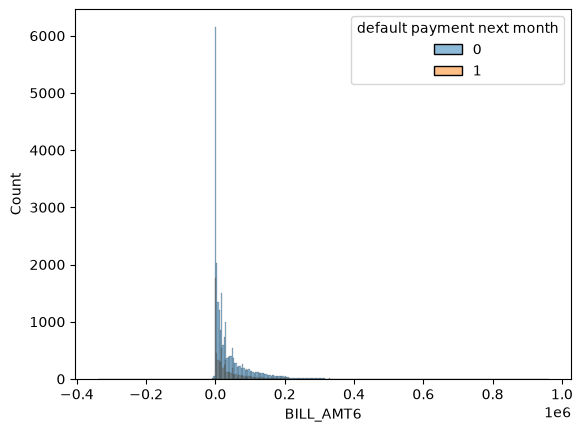

In [36]:
sns.histplot(data=raw_data, x="BILL_AMT6", hue="default payment next month")

<Axes: xlabel='PAY_AMT6', ylabel='Count'>

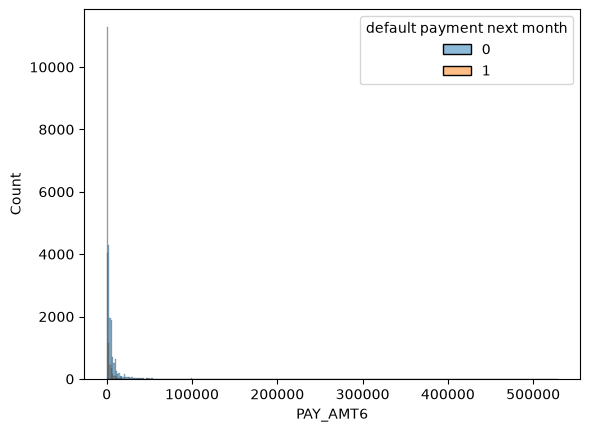

In [38]:
sns.histplot(data=raw_data, x="PAY_AMT6", hue="default payment next month")

<Axes: xlabel='LIMIT_BAL', ylabel='Count'>

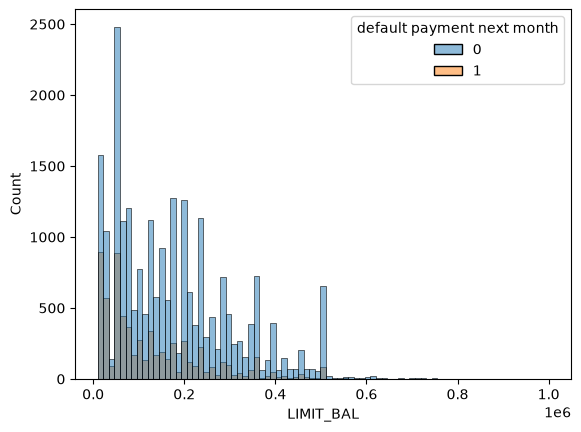

In [37]:
sns.histplot(data=raw_data, x="LIMIT_BAL", hue="default payment next month")

<Axes: xlabel='EDUCATION', ylabel='count'>

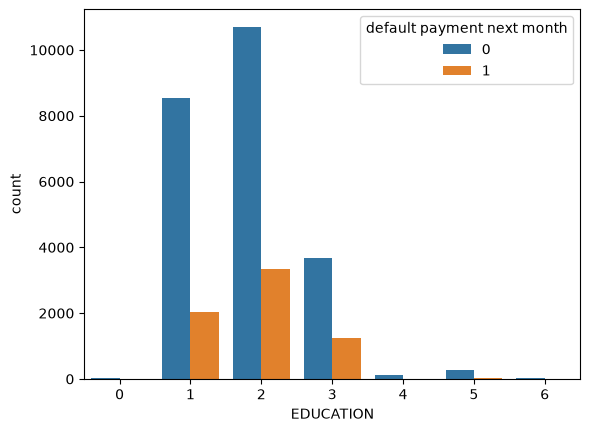

In [33]:
sns.countplot(data=raw_data, x="EDUCATION", hue="default payment next month")

### 2.b Analyse bivariée

### Vérification de la cohérance et Imputation

Dans un premier temps l'imputation des valeurs se fera sur des choix arbitraire.
Dans un second temps des méthodes d'imputation basé sur les plus proches voisins et d'autres choix arbitraires seront expérimentées.

Pour la variable Mariage, la valeur 0 est non-documentée et relativament peu présente, avec environ 0.2% du dataset. Donc on décide d'imputer 3, qui est la catégorie 'autre'.

Pour la variable Education, les valeur 0, 5 et 6 sont non-documentées et relativament peu présente, avec environ 1% du dataset. Donc on décide d'imputer la valeur 4, qui est la catégorie 'autre'.

### Liste des choix effectué :

Variable x1 créer car ....
Valeur v interprêtée commme ...


Ces choix n'étant pas neutre et influençant la qualité des modèles, il est important de les garder en tête et de les concidérer dans l'analyse et l'interprêtation des résultats.